# 04 — EMT-TF expression (unconditional readout)
Categorical overlay of thresholded EMT-TF expressers on a grey manifold. Panel spans Snail/Zeb/Twist **and** the FOXC / PRRX mesenchymal families (VIM is a mesenchymal marker, not a TF — excluded). Gated on detectable expression; the arm-demarcating early/late pair is derived.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)
from scipy.stats import spearmanr

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)        # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)  # h5ads
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Filbin2018_Brain | category: Brain


### Load signatures; use the house linear layout

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 2259 | pseudotime range 0.0 -> 9.9


### Candidate EMT-TF panel — detection-gated, pseudotime-profiled
Include FOXC/PRRX families, not just Snail/Zeb/Twist. Report fraction expressing and early/late means; pick the two factors best demarcating the developmental ends among detectable TFs.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0; rho,p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nderived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 FOXC2      0.004       0.028      0.004    -0.040    EARLY(root)
 FOXC1      0.003       0.011      0.001    -0.018    EARLY(root)
TWIST2      0.001       0.002      0.000    -0.011    EARLY(root)
TWIST1      0.002       0.002      0.013     0.020 LATE(terminus)
 PRRX2      0.012       0.027      0.039     0.023 LATE(terminus)
 SNAI2      0.032       0.134      0.154     0.033 LATE(terminus)
 SNAI1      0.081       0.319      0.329     0.048 LATE(terminus)
 PRRX1      0.565       2.010      2.212     0.074 LATE(terminus)
  ZEB1      0.785       3.005      3.868     0.127 LATE(terminus)
  ZEB2      0.772       2.432      3.325     0.160 LATE(terminus)

derived pair: SNAI2 (early/root) <-> ZEB2 (late/terminus)


### Deliverable — `expression.pdf` (categorical overlay, display cutoffs at upper-quartile among expressers)

overlay thresholds (upper quartile among expressers): {'SNAI2': 5.403, 'ZEB2': 4.747} | cells shown: {'SNAI2': 18, 'ZEB2': 436}
SNAI2: 3.2% expressing; 18 shown (upper quartile), mean pseudotime of shown cells = 0.41 (all cells = 0.47)
ZEB2: 77.2% expressing; 436 shown (upper quartile), mean pseudotime of shown cells = 0.46 (all cells = 0.47)
shown-cell pseudotime separation = 0.05
saved expression.pdf


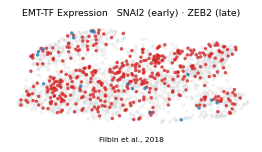

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) · {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Filbin et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
print(f'shown-cell pseudotime separation = {abs(tn[sel[late_tf]].mean() - tn[sel[early_tf]].mean()):.2f}')
print('saved expression.pdf')